<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/01_Network_Intrusion_Detection/QNN_PowerSystemIDS_Peng2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# VDAO-QNN for power-system intrusion detection: Peng, Qiu and Li (2025) step by step

This notebook re-implements, runs and checks the method of

> Lian Peng, Meikang Qiu and Chong Li, "Intrusion Detection of Power Systems with Quantum Neural Networks",
> *2025 IEEE International Conference on Systems, Man, and Cybernetics (SMC)*, Vienna, 5-8 October 2025,
> pp. 4818-4823. DOI 10.1109/SMC58881.2025.11342482.

The paper publishes no code. Everything below is written from its description (Sections III to V, Figs. 1 and 4 to 8,
Table I). The authors used **PennyLane** on a CPU simulator; so does this notebook (the circuit is a real PennyLane
QNode, drawn and checked below), plus a small hand-written NumPy state-vector engine that computes *exactly the same
circuit and the same gradients* about 20 times faster, so that thousands of training steps fit into a class session.
A cell proves the equivalence (outputs and parameter-shift gradients) before the fast engine is used.

**What the notebook does.** It downloads the public *IEC 60870-5-104 Intrusion Detection Dataset* (the "Balanced IEC104
Train/Test CSV Files" package the paper names, Zenodo record 7108614), builds for each of the paper's 11 attack types
a binary problem "normal flow vs this attack", encodes each flow into a **7-qubit amplitude-encoded state**
(111 features padded to 128 amplitudes), and trains the paper's **6-layer, 42-parameter variational circuit** with the
two ideas of the paper:

1. the **accuracy-enhancement cost function** `C = MSE * (1 - A_batch)`,
2. the **validation-accuracy-decisive (VAD) module**: after training, pick the epoch with the best mean training
   accuracy, evaluate all parameter sets recorded in that epoch on a validation set and keep the best one.

It then re-creates the paper's evidence: the 11-attack accuracy table against LR / KNN / GNB / ANN (Table I), the
ablations of the cost function (Fig. 7) and of the VAD module (Fig. 8), the validation-versus-test correlation, the
"output hovers near zero while validation accuracy climbs" picture (Fig. 1) and the gradient statistics (Fig. 6).
Every claim gets an explicit verdict.

**How to run.** Google Colab, CPU runtime, *Runtime -> Run all*. `FAST_MODE = True` (the setting in the configuration cell) finishes in a few minutes; `FAST_MODE = False` uses the larger budgets documented in the configuration cell.
The dataset is public (no Hugging Face token needed).

**What you get at the end.** A table with the paper's numbers next to the notebook's, confusion matrices, the paper's
figures re-drawn from your own run, and an honest verdict per claim, followed by a critical reading and exercises.

## The paper in one page

**Problem.** Detect attacks on the IEC 60870-5-104 (IEC-104) protocol that is used in power-grid SCADA networks.
The dataset has twelve classes (normal traffic plus twelve... see below: 11 attack types in the balanced package);
the paper evaluates **one binary problem per attack type** (Table I has 11 rows).

**Data (Section III).** "BalancedIEC104 Train Test CSV Files" of the IEC 60870-5-104 Intrusion Detection Dataset. The
paper says nothing about which of the 24 CSV files (CICFlowMeter or custom IEC-104 parser; flow timeout 15 to 180 s)
it used.

**Preprocessing (Section III-B).** Winsorisation (to tame feature values that differ by orders of magnitude) followed
by `MinMaxScaler`. **Encoding (Section III-C):** amplitude encoding, `n` features into `ceil(log2 n)` qubits.

**Model (Section IV, Figs. 4 and 5).** Six layers, 42 parameterised gates ("much higher than 25"), linear nearest-neighbour
CNOT coupling in the first four layers and an "alternate-qubit-pair omission" (sparse entanglement, like dropout) in the
last two layers. **Local measurement:** only qubit q0 is measured, observable Pauli-Z. Labels are +1 / -1.
**Cost:** `C_MSE * (1 - A)` where `A` is the accuracy of the current training batch (eq. 6 and 8). **Optimiser:**
Adam-type adaptive optimiser, learning rate 0.005, batch size 10 (Section V). Gradients by the parameter-shift rule.
**VAD module (Section IV-C):** log accuracy and parameters of every batch; after training take the epoch with the highest
mean training accuracy, validate every configuration of that epoch and deploy the best.

**Claims to check.**
1. Table I: VDAO-QNN accuracy for 11 attack types, between 96.61 % and 98.52 % in the table (abstract: 96.8 % to 99.5 %).
2. Against LR, KNN, GNB and ANN the QNN "outperforms classical models overall in non-DoS scenarios" (best in 2 of
   5 non-DoS types) and is "consistent", while the classical models differ strongly between DoS and non-DoS.
3. Fig. 7: the accuracy-enhancement cost beats plain MSE.
4. Fig. 8: the best-epoch (VAD) parameters beat the final-epoch parameters on test accuracy, and validation and test
   accuracy are strongly correlated.
5. Fig. 1: the circuit output oscillates near zero while validation accuracy approaches 1.
6. Fig. 6: gradients cluster around 0 with a standard deviation of roughly 0.008, stable over training (no barren plateau).

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Framework | PennyLane (+ JAX), Python 3.10, Vertex AI n2-standard-8 | PennyLane QNode for the drawing and for an equivalence check; the training loop uses a NumPy re-implementation of the same circuit and the same analytic (parameter-shift) gradient (`# CHOICE`, checked to 1e-12) |
| Dataset | Balanced IEC104 Train/Test CSV Files, 11 attack types | the same package (Zenodo 7108614), the public mirror of the IEEE DataPort dataset |
| Which CSV | not stated | `# CHOICE:` custom IEC-104 parser features, 60 s flow timeout (`FEATURE_SET`, `TIMEOUT_S` in the config cell) |
| Task | binary per attack type | `# CHOICE:` "NORMAL vs attack k", the 492 normal and 492 attack training flows and 210 + 210 test flows of that attack |
| Winsorisation | yes, limits not stated | `# CHOICE:` clip every feature to the 1st and 99th percentile of the **training** split |
| Scaling | MinMaxScaler | MinMax to [0, 1] fitted on the training split; test values clipped to [0, 1] |
| Encoding | amplitude encoding, `ceil(log2 n)` qubits | 111 features zero-padded to 128 amplitudes, L2-normalised, 7 qubits |
| Circuit | 6 layers, 42 parameterised gates, linear CNOT coupling in layers 1-4, sparse coupling in layers 5-6, q0 + Pauli-Z (Fig. 5 is only a picture) | `# CHOICE:` one `RY` per qubit and layer (6 x 7 = 42 parameters); CNOT chain pointing towards q0 (`CNOT(i+1 -> i)`, applied for `i = 5 ... 0`) in layers 1-4; layer 5 keeps the pairs `i = 4, 2, 0`, layer 6 keeps `i = 2, 0` |
| Initial parameters | not stated | `# CHOICE:` uniform in [0, 2 pi) |
| Cost | `MSE * (1 - A)` with labels +-1 | exactly that; `A` is the accuracy of the batch at the current parameters and is treated as a constant in the gradient |
| Optimiser | learning rate 0.005, batch 10, optimiser not named | Adam (`beta1 = 0.9, beta2 = 0.999`), learning rate 0.005, batch size 10 |
| Epochs | Fig. 1 shows about 10,000 steps | `EPOCHS` in the config cell (the budget is smaller than 10,000 steps, see there) |
| Validation set | not described | `# CHOICE:` 20 % of the training flows, stratified, held out from training |
| VAD tie-breaking | not described | `# CHOICE:` the latest epoch / latest batch wins ties |
| Classical baselines | LR, KNN, GNB, ANN (settings not stated) | scikit-learn `LogisticRegression`, `KNeighborsClassifier(5)`, `GaussianNB`, `MLPClassifier((64,))`, additionally `RandomForest` and `SVC(rbf)`; trained on the same preprocessed features, and on the same amplitude-encoded vectors |
| Seeds | not stated | `SEED = 42` plus extra seeds in full mode |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn and matplotlib.
# The pip line runs on Colab (or wherever a package is missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
MISSING = [m for m in ("pennylane", "py7zr", "requests") if importlib.util.find_spec(m) is None]
if IN_COLAB or MISSING:
    %pip install -q "pennylane==0.45.1" "py7zr==1.1.4" requests
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("pennylane, py7zr and requests already present; skipping pip install.")

pennylane, py7zr and requests already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = True            # True: class demo in a few minutes. False: larger budgets (see below).
SEED      = 42              # CHOICE: the paper reports no seed
DATA_DIR  = "iec104_data"   # downloaded and extracted data live here (never inside a git checkout)
IBM_TOKEN = ""              # unused: the paper is simulator-only; kept for template compatibility

# ---- data choices (the paper does not say which CSV it used) ----
FEATURE_SET = "custom"      # CHOICE: "custom" = IEC-104 parser features (111 columns), "cic" = CICFlowMeter features (76 usable columns)
TIMEOUT_S   = 60            # CHOICE: flow timeout of the CSV pair: 15, 30, 60, 90, 120 or 180
WINSOR      = (0.01, 0.99)  # CHOICE: winsorisation quantiles, fitted on the training split
VAL_FRAC    = 0.2           # CHOICE: share of the training flows held out as validation set for the VAD module

# ---- paper settings (kept identical in both modes) ----
N_QUBITS   = 7              # ceil(log2(111 or 76)) = 7 -> 128 amplitudes
N_LAYERS   = 6              # paper Section IV-A / Fig. 5
LR         = 0.005          # paper Section V
BATCH_SIZE = 10             # paper Section V

ATTACKS = ["c_ci_na_1", "c_rd_na_1", "c_rp_na_1", "c_se_na_1", "c_sc_na_1",                       # paper Table I, non-DoS
           "c_ci_na_1_DoS", "c_rd_na_1_DoS", "c_rp_na_1_DoS", "c_sc_na_1_DoS", "c_se_na_1_DoS", "m_sp_na_1_DoS"]  # DoS
EXAMPLE_ATTACK = "c_ci_na_1_DoS"   # the paper illustrates the gradients (Fig. 6) with "a DoS intrusion attack"
FIG8_ATTACKS   = ["c_ci_na_1", "c_rd_na_1", "c_rp_na_1", "c_se_na_1"]   # CHOICE: the paper compares "four selected attack types"

# ---- budgets that depend on the mode ----
if FAST_MODE:
    EPOCHS = 4               # 4 epochs x 78 batches = 312 Adam steps per run (the paper's Fig. 1 shows ~10,000)
    SEEDS  = [SEED]
else:
    EPOCHS = 16              # 1,248 Adam steps per run; all 22 runs of one seed take about 30 to 60 minutes on a shared CPU (a full run was not completed within the 2 h limit of the validation session on a heavily shared CPU, so the published outputs are FAST_MODE outputs)...
    SEEDS  = [SEED, SEED + 1]   # ... times the number of seeds. For a paper-scale budget raise EPOCHS to 130 (~10,000 steps) (mean and std over seeds are reported)
print("FAST_MODE =", FAST_MODE, "| epochs per run =", EPOCHS, "| seeds =", SEEDS)

FAST_MODE = True | epochs per run = 4 | seeds = [42]


In [3]:
import os, time, glob, warnings
os.environ.setdefault("OMP_NUM_THREADS", "1")      # tiny matrices: single-threaded BLAS is faster and friendlier to shared CPUs
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import sklearn, requests
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

import pennylane as qml
from pennylane import numpy as pnp

np.random.seed(SEED)
rng = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
T_NOTEBOOK_START = time.time()
print("pennylane", qml.__version__, "| numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

pennylane 0.45.1 | numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1


## 1. The IEC 60870-5-104 Intrusion Detection Dataset

Every row is one **network flow** between a SCADA master and its outstations in an emulated power-grid testbed
(University of Western Macedonia), described either by CICFlowMeter statistics (76 usable columns) or by statistics
computed by a custom IEC-104 parser (111 columns: inter-arrival times, APDU lengths, counts of I/S/U-format messages,
causes of transmission, ASDU type groups). The label is `NORMAL` or the name of an attack type. The attack types are named
after the IEC-104 ASDU type they abuse (`c_ci_na_1` = interrogation command, `c_rd_na_1` = read command,
`c_rp_na_1` = reset-process command, `c_sc_na_1` = single command, `c_se_na_1` = set-point command, `m_sp_na_1` =
single-point information), each attack either as a command-injection / MITM variant or with the suffix `_DoS` as a
flooding variant.

The "Balanced" package contains, for each of six flow timeouts, a training and a test CSV whose 12 classes
(normal plus 11 attacks) have exactly the same number of flows. It is **public** on Zenodo (no login, no Hugging Face
token needed). If a reader wants to use another copy, set `DATA_DIR` to a folder that already contains the extracted
`iec104_train_test_csvs` folder, or upload the 7z file into `DATA_DIR` as `bal.7z`.

In [4]:
ZENODO_URLS = ["https://zenodo.org/api/records/7108614/files/Balanced_IEC104_Train_Test_CSV_Files.7z/content",
               "https://zenodo.org/records/7108614/files/Balanced_IEC104_Train_Test_CSV_Files.7z?download=1"]
ARCHIVE = os.path.join(DATA_DIR, "bal.7z")
EXTRACT = os.path.join(DATA_DIR, "x")

def download(path, urls):
    for url in urls:
        try:
            with requests.get(url, stream=True, timeout=120) as r:
                r.raise_for_status()
                with open(path, "wb") as fh:
                    for chunk in r.iter_content(1 << 20):
                        fh.write(chunk)
            if os.path.getsize(path) > 1_000_000:
                return url
        except Exception as e:
            print("download failed from", url.split("/")[2], "->", type(e).__name__, str(e)[:100])
    raise RuntimeError("Could not download the dataset. Download Balanced_IEC104_Train_Test_CSV_Files.7z from "
                       "https://zenodo.org/records/7108614 and save it as " + ARCHIVE)

def find_csv(kind, timeout_s, split):
    pat = os.path.join(EXTRACT, "**", f"tests_{kind}_{timeout_s}", f"*{split}*.csv")
    hits = glob.glob(pat, recursive=True)
    if not hits:
        raise FileNotFoundError(pat)
    return hits[0]

if not glob.glob(os.path.join(EXTRACT, "**", "tests_custom_60"), recursive=True):
    if not os.path.exists(ARCHIVE):
        t0 = time.time(); used = download(ARCHIVE, ZENODO_URLS)
        print(f"downloaded {os.path.getsize(ARCHIVE)/1e6:.1f} MB from {used.split('/')[2]} in {time.time()-t0:.0f} s")
    import py7zr
    with py7zr.SevenZipFile(ARCHIVE) as z:
        z.extractall(EXTRACT)
    print("extracted to", EXTRACT)

train_raw = pd.read_csv(find_csv(FEATURE_SET, TIMEOUT_S, "train"), low_memory=False)
test_raw  = pd.read_csv(find_csv(FEATURE_SET, TIMEOUT_S, "test"), low_memory=False)
ID_COLS = ['Flow ID', 'Src IP', 'Src Port', 'Dst IP', 'Dst Port', 'Protocol', 'Timestamp']   # CIC files only: identifiers are dropped
FEATS = [c for c in train_raw.columns if c not in ID_COLS + ["Label"]]
assert len(FEATS) <= 2 ** N_QUBITS, "more features than amplitudes"
print("train", train_raw.shape, "| test", test_raw.shape, "| features used:", len(FEATS))

train (5904, 112) | test (2520, 112) | features used: 111


## 2. Preprocessing and amplitude encoding

For one binary problem (NORMAL vs attack `k`) we take the training flows of those two classes and their test flows.
All statistics are **fitted on the training flows only**:

1. **Winsorisation**: every feature is clipped to its 1st and 99th training percentile (test values are clipped with the
   same limits).
2. **MinMaxScaler** to [0, 1] (test values clipped to [0, 1]).
3. **Amplitude encoding**: the vector is padded with zeros to 128 entries and divided by its L2 norm, so that its entries
   are the amplitudes of a 7-qubit state `|psi(x)> = sum_j x_j |j>`. In PennyLane this is `qml.AmplitudeEmbedding`
   (the notebook normalises explicitly so that the classical baselines can use exactly the same vectors).
4. The labels become +1 (attack) and -1 (normal), the validation split is a stratified 20 % of the training flows.

In [5]:
def winsorise_scale(Xtr, Xte, q=WINSOR):
    lo, hi = np.quantile(Xtr, q[0], axis=0), np.quantile(Xtr, q[1], axis=0)       # fitted on the training split only
    Xtr, Xte = np.clip(Xtr, lo, hi), np.clip(Xte, lo, hi)
    sc = MinMaxScaler().fit(Xtr)
    return sc.transform(Xtr), np.clip(sc.transform(Xte), 0.0, 1.0)

def to_amplitudes(X):
    Z = np.zeros((len(X), 2 ** N_QUBITS)); Z[:, :X.shape[1]] = X
    n = np.linalg.norm(Z, axis=1); Z[n == 0, 0] = 1.0; n[n == 0] = 1.0           # guard: an all-zero row would not be a state
    return Z / n[:, None]

def prepare_pair(attack):
    a = train_raw[train_raw.Label.isin(["NORMAL", attack])]
    b = test_raw[test_raw.Label.isin(["NORMAL", attack])]
    Xa = a[FEATS].apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan).fillna(0.0).to_numpy(float)
    Xb = b[FEATS].apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan).fillna(0.0).to_numpy(float)
    Fa, Fb = winsorise_scale(Xa, Xb)                                              # features in [0, 1]
    ya = np.where(a.Label.to_numpy() == "NORMAL", -1.0, 1.0)
    yb = np.where(b.Label.to_numpy() == "NORMAL", -1.0, 1.0)
    return dict(Ftr=Fa, ytr=ya, Fte=Fb, yte=yb, Atr=to_amplitudes(Fa), Ate=to_amplitudes(Fb))

PAIRS = {att: prepare_pair(att) for att in ATTACKS}
p = PAIRS[ATTACKS[0]]
print({k: v.shape for k, v in p.items()})
print("amplitude vectors have unit norm:", np.allclose(np.linalg.norm(p['Atr'], axis=1), 1.0))

{'Ftr': (984, 111), 'ytr': (984,), 'Fte': (420, 111), 'yte': (420,), 'Atr': (984, 128), 'Ate': (420, 128)}
amplitude vectors have unit norm: True


## Dataset Exploration and Visualisation

Everything below shows **real flows** of the IEC-104 dataset with their ground-truth labels; nothing is simulated.
First the shapes, feature names and original labels, then the class distribution, then 2-D projections of the real flows
coloured by their true class. The model uses **amplitude encoding**, not angle encoding, so there is no [0, pi]-scaled
angle plot; instead the second projection shows the actual model input (the L2-normalised 128-dimensional vectors).

Training CSV: 5904 flows x 112 columns | test CSV: 2520 flows
111 feature names used by the model (custom parser, flow timeout 60 s):
flow idle time max, flow idle time min, flow idle time mean, flow idle time std, flow idle time variance, flow active time max, flow active time min, flow active time mean, flow active time std, flow active time variance, flow IAT max, fw IAT max, bw IAT max, flow IAT min, fw IAT min, bw IAT min, flow IAT mean, fw IAT mean, bw IAT mean, flow IAT std, fw IAT std, bw IAT std, flow IAT tot, fw iAT tot, bw IAT tot, flow iec104 packts/s, fw iec104 packts/s, bw iec104 packts/s, flow iec104 bytes/s, fw iec104 bytes/s, bw iec104 bytes/s, flow packet APDU length max, flow packet APDU length min, flow packet APDU length mean, flow packet APDU length std, flow packet APDU length var, fw packet APDU length max, fw packet APDU length min, fw packet APDU length mean, fw packet APDU length std, fw packet APDU length var, bw packet APDU length max, bw packet APDU length


Original label values (12 distinct) and class counts:


Label,NORMAL,c_ci_na_1,c_rd_na_1,c_rp_na_1,c_se_na_1,c_sc_na_1,c_ci_na_1_DoS,c_rd_na_1_DoS,c_rp_na_1_DoS,c_sc_na_1_DoS,c_se_na_1_DoS,m_sp_na_1_DoS
train,492,492,492,492,492,492,492,492,492,492,492,492
test,210,210,210,210,210,210,210,210,210,210,210,210


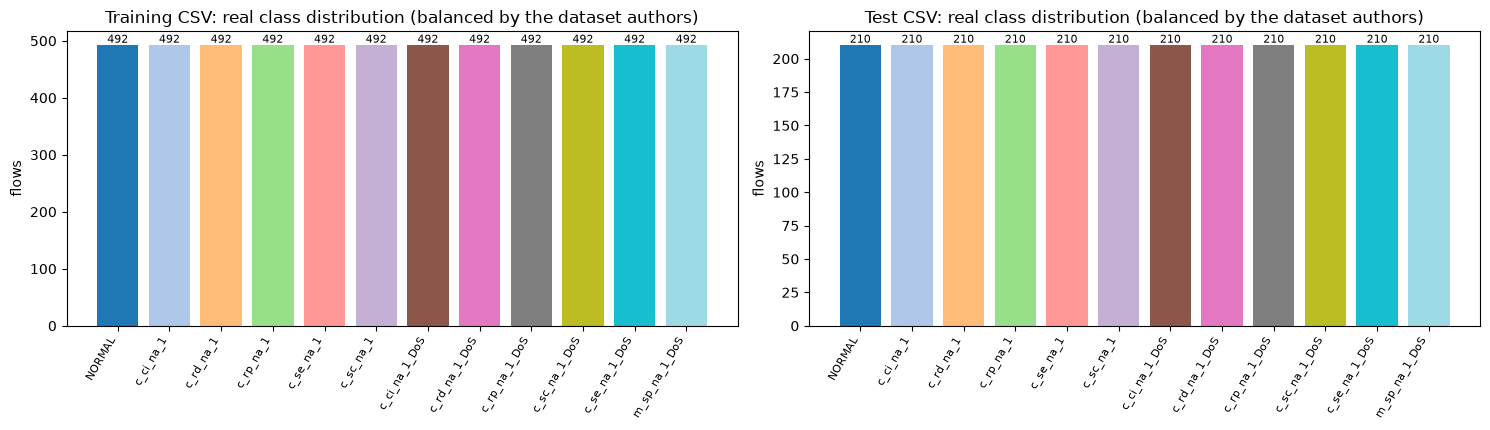

In [6]:
print(f"Training CSV: {train_raw.shape[0]} flows x {train_raw.shape[1]} columns | test CSV: {test_raw.shape[0]} flows")
print(f"{len(FEATS)} feature names used by the model ({FEATURE_SET} parser, flow timeout {TIMEOUT_S} s):")
print(", ".join(FEATS))
counts = pd.concat([train_raw.Label.value_counts().rename("train"), test_raw.Label.value_counts().rename("test")], axis=1)
counts = counts.reindex(["NORMAL"] + ATTACKS[:5] + ATTACKS[5:])
print(f"\nOriginal label values ({counts.shape[0]} distinct) and class counts:")
display(counts.T)

colors = dict(zip(["NORMAL"] + ATTACKS, plt.cm.tab20(np.linspace(0, 1, 12))))
fig, axes = plt.subplots(1, 2, figsize=(15, 4.4), sharey=False)
for ax, col, title in zip(axes, ["train", "test"], ["Training CSV", "Test CSV"]):
    ax.bar(range(len(counts)), counts[col].values, color=[colors[k] for k in counts.index])
    ax.set_xticks(range(len(counts))); ax.set_xticklabels(counts.index, rotation=60, ha="right", fontsize=8)
    ax.set_ylabel("flows"); ax.set_title(f"{title}: real class distribution (balanced by the dataset authors)")
    for i, v in enumerate(counts[col].values): ax.text(i, v, str(v), ha="center", va="bottom", fontsize=8)
plt.tight_layout(); plt.show()

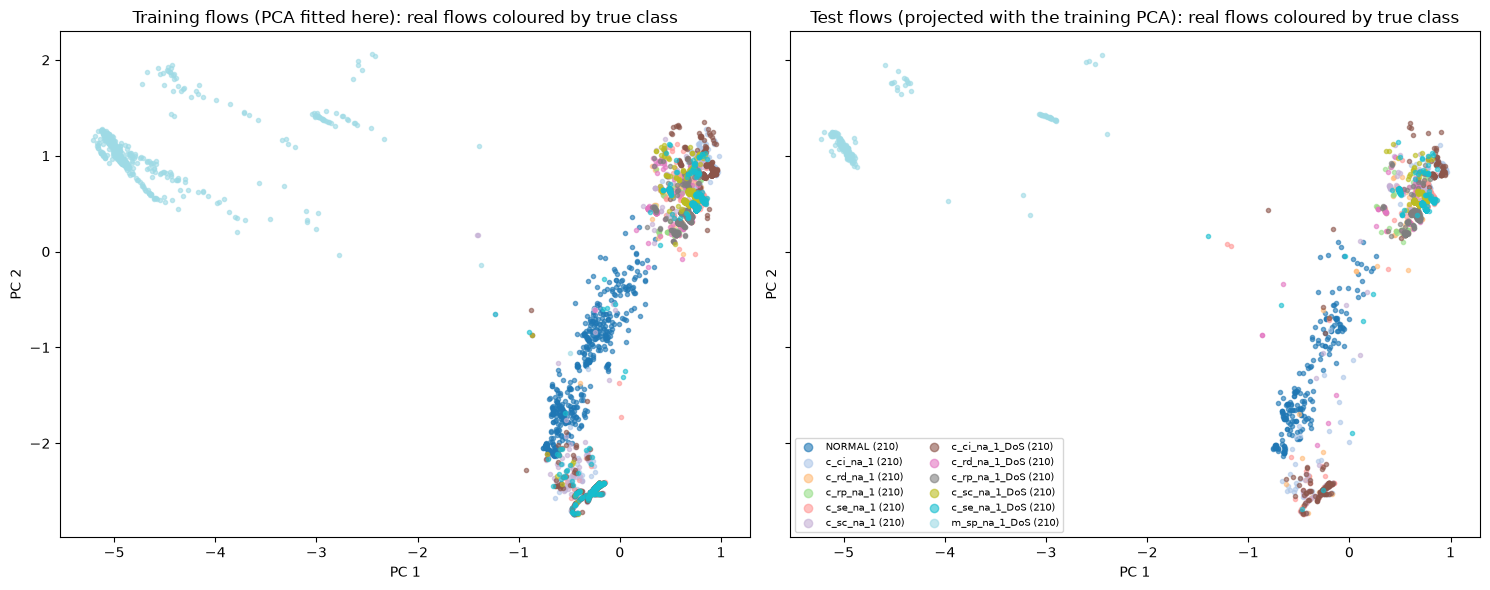

explained variance of the two components (training split): [0.386 0.231]


In [7]:
# 2-D projection 1: all 12 real classes, raw PCA coordinates fitted on the TRAINING split (features winsorised + scaled on train).
Xtr_all = train_raw[FEATS].apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan).fillna(0.0).to_numpy(float)
Xte_all = test_raw[FEATS].apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan).fillna(0.0).to_numpy(float)
Ftr_all, Fte_all = winsorise_scale(Xtr_all, Xte_all)
pca_all = PCA(n_components=2, random_state=SEED).fit(Ftr_all)
Ptr, Pte = pca_all.transform(Ftr_all), pca_all.transform(Fte_all)
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharex=True, sharey=True)
for ax, P, lab, title in [(axes[0], Ptr, train_raw.Label.to_numpy(), "Training flows (PCA fitted here)"),
                          (axes[1], Pte, test_raw.Label.to_numpy(), "Test flows (projected with the training PCA)")]:
    for k in ["NORMAL"] + ATTACKS:
        m = lab == k
        ax.scatter(P[m, 0], P[m, 1], s=9, alpha=0.6, color=colors[k], label=f"{k} ({m.sum()})")
    ax.set_title(title + ": real flows coloured by true class"); ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2")
axes[1].legend(fontsize=7, markerscale=2, loc="best", ncol=2)
plt.tight_layout(); plt.show()
print("explained variance of the two components (training split):", np.round(pca_all.explained_variance_ratio_, 3))

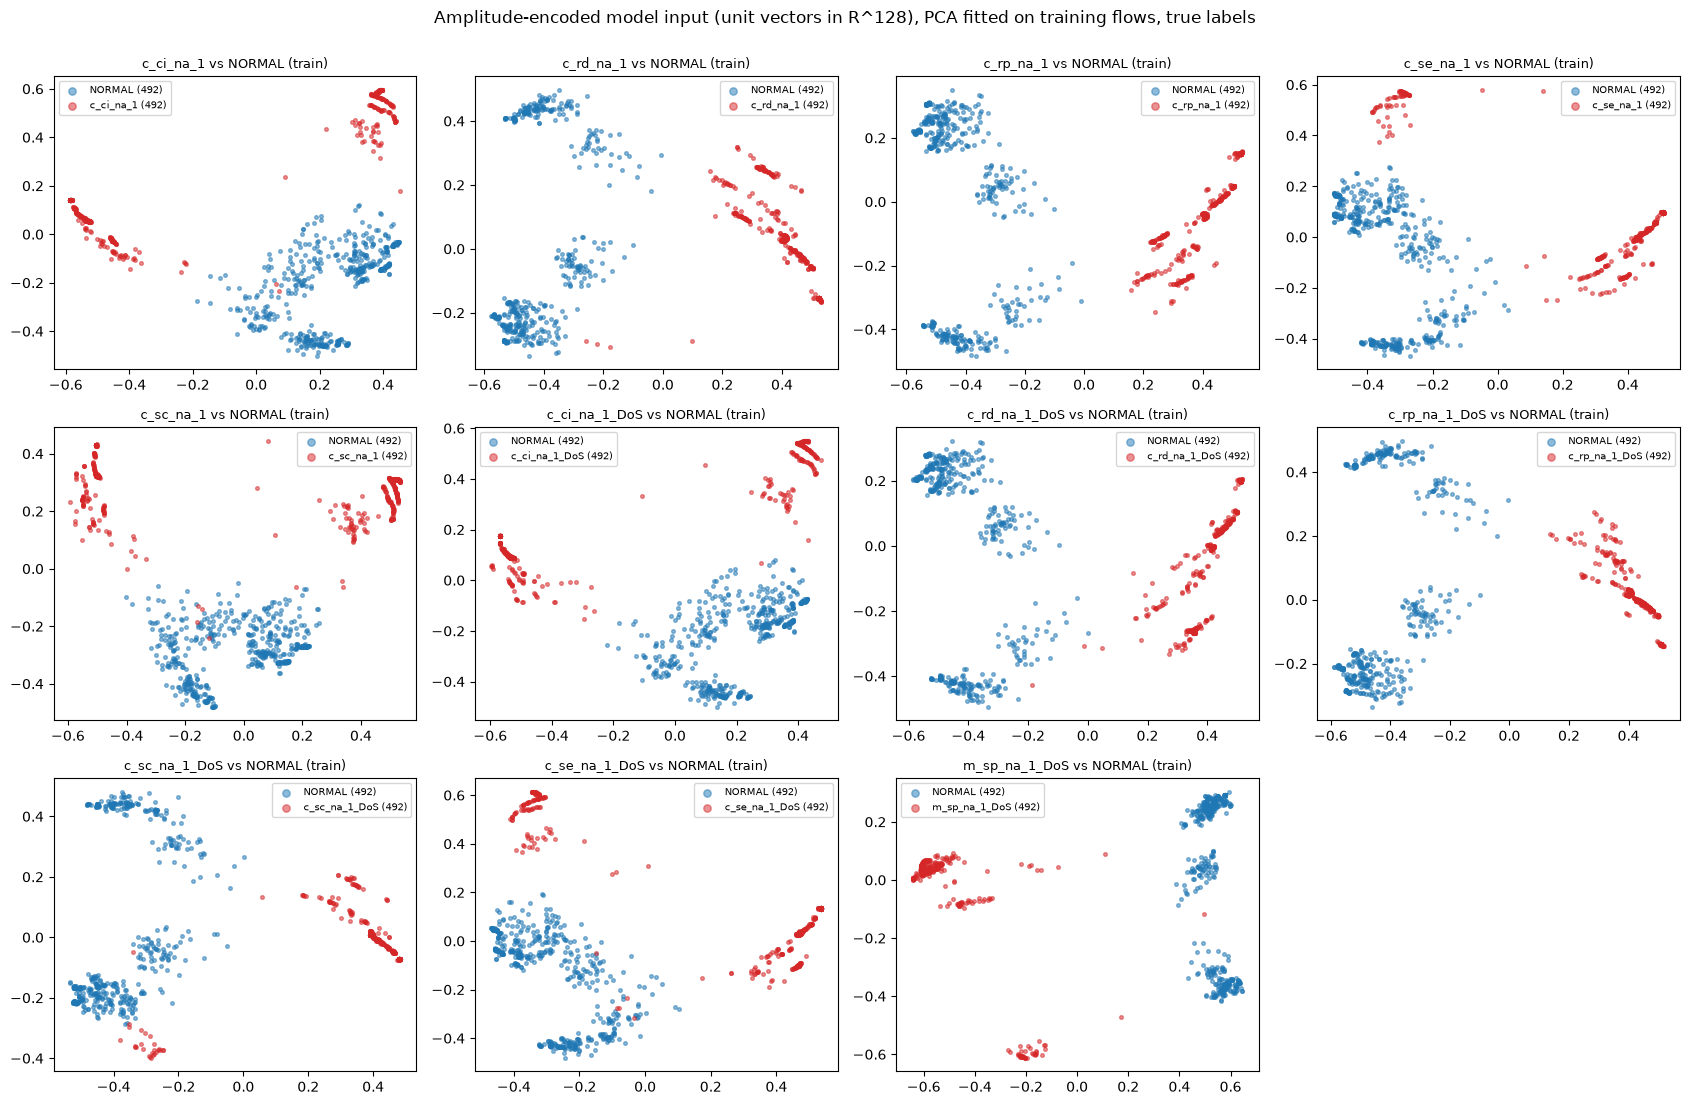

In [8]:
# 2-D projection 2: the actual model input. For every binary problem, PCA of the amplitude-encoded vectors (fitted on that
# problem's training flows), real flows coloured by ground truth: grey = NORMAL, red = the attack.
fig, axes = plt.subplots(3, 4, figsize=(17, 11)); axes = axes.ravel()
for ax, att in zip(axes, ATTACKS):
    P = PAIRS[att]; pc = PCA(n_components=2, random_state=SEED).fit(P["Atr"])
    Z = pc.transform(P["Atr"])
    for val, name, c in [(-1, "NORMAL", "tab:blue"), (1, att, "tab:red")]:
        m = P["ytr"] == val
        ax.scatter(Z[m, 0], Z[m, 1], s=7, alpha=0.5, color=c, label=f"{name} ({m.sum()})")
    ax.set_title(att + " vs NORMAL (train)", fontsize=9); ax.legend(fontsize=7, markerscale=2)
axes[-1].axis("off")
fig.suptitle("Amplitude-encoded model input (unit vectors in R^128), PCA fitted on training flows, true labels", y=1.0)
plt.tight_layout(); plt.show()

## Quantum Circuit Architecture

The circuit of the paper (Fig. 5) is drawn only as a picture, so the exact gate wiring is a `# CHOICE:` documented in the
table above. What is fixed by the text: 7 qubits (amplitude encoding of 111 features), **6 layers**, **42 parameterised
gates**, linear nearest-neighbour CNOT coupling in the first four layers, a sparse "alternate pair omitted" coupling in
the last two, a local measurement of qubit q0 with Pauli-Z. The cell below defines the circuit **once as a PennyLane
QNode**, draws that very QNode, prints qubit count, depth and parameter count, and then proves that the fast NumPy engine
used for training computes the same outputs and the same parameter-shift gradients.

Matplotlib is building the font cache; this may take a moment.


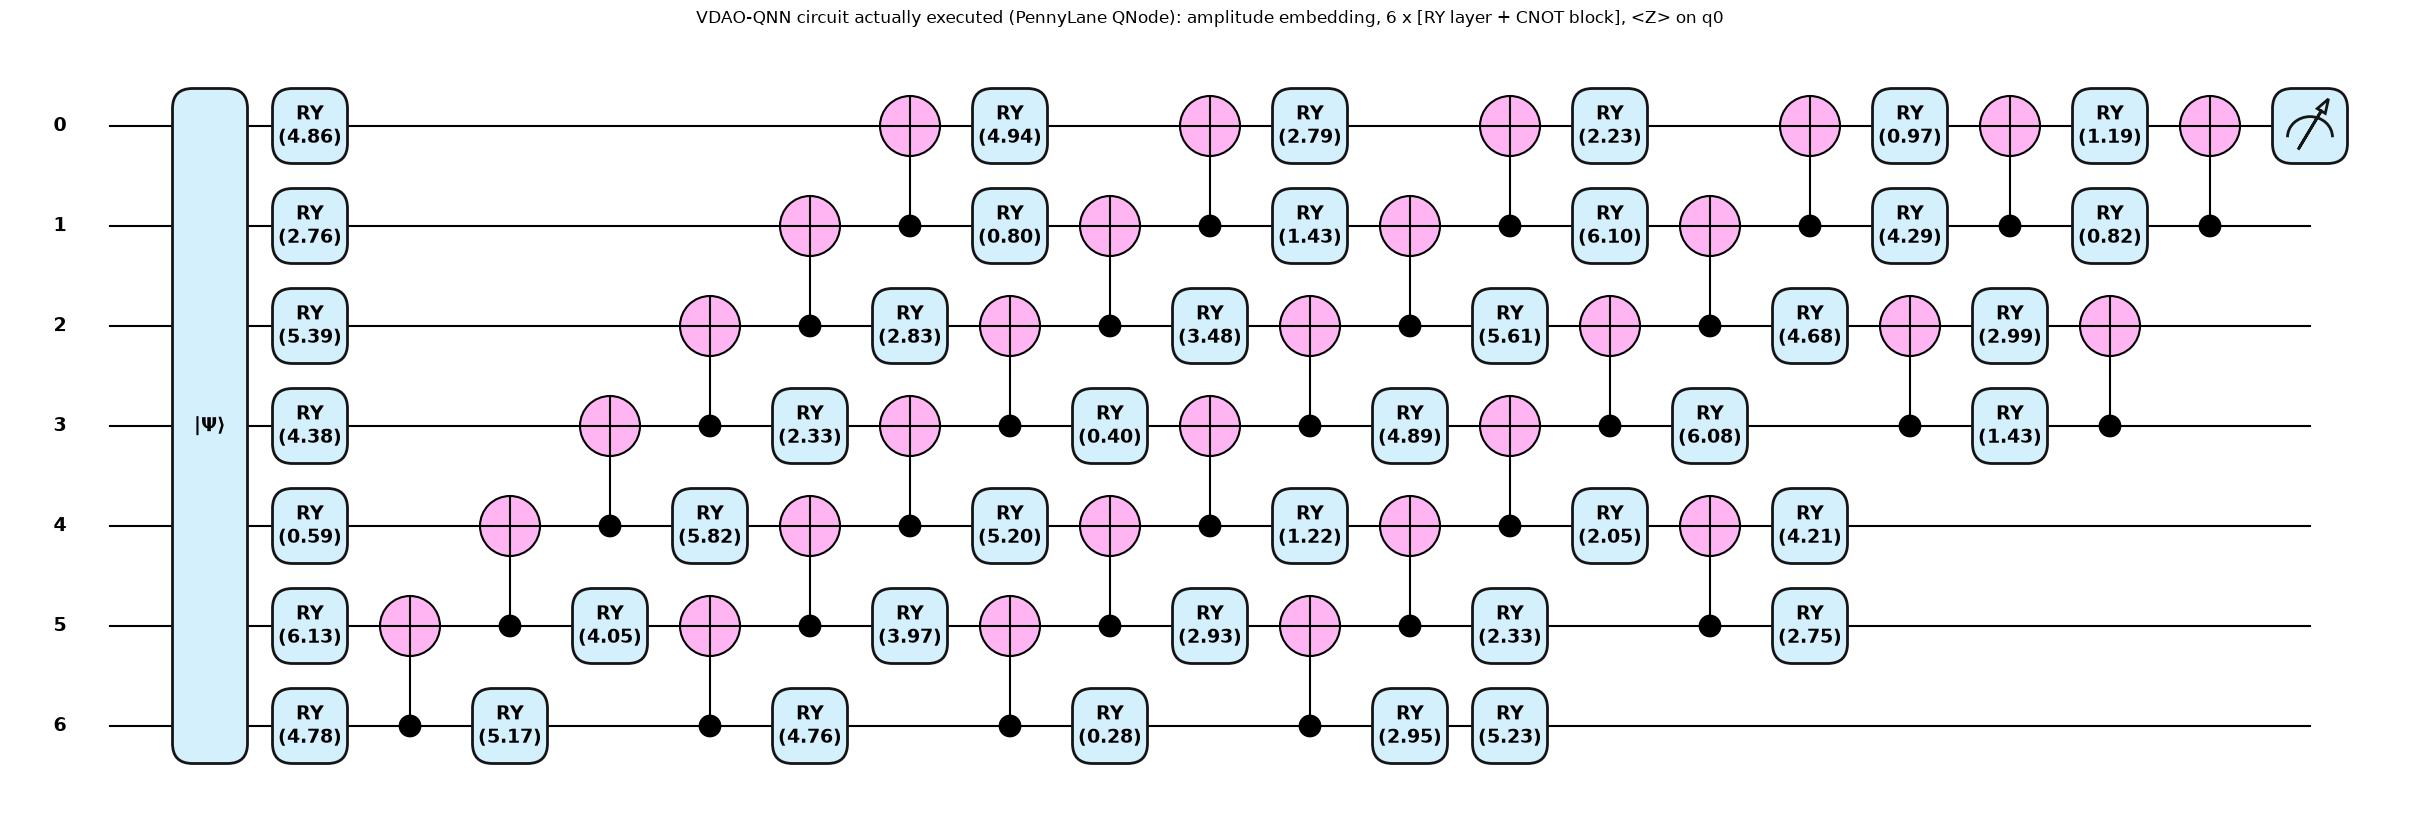

qubits               : 7
trainable parameters : 42 (RY gates: 42 )
gate counts          : {'AmplitudeEmbedding': 1, 'RY': 42, 'CNOT': 29}
circuit depth        : 21 (including the amplitude-embedding block)
entangler pairs per layer: [[(6, 5), (5, 4), (4, 3), (3, 2), (2, 1), (1, 0)], [(6, 5), (5, 4), (4, 3), (3, 2), (2, 1), (1, 0)], [(6, 5), (5, 4), (4, 3), (3, 2), (2, 1), (1, 0)], [(6, 5), (5, 4), (4, 3), (3, 2), (2, 1), (1, 0)], [(5, 4), (3, 2), (1, 0)], [(3, 2), (1, 0)]]


In [9]:
def entangler_targets(layer):
    # CHOICE: CNOT(control=i+1 -> target=i), applied for i = N-2 ... 0, i.e. a chain pointing towards the output qubit q0.
    idx = list(range(N_QUBITS - 2, -1, -1))
    if layer == 4: idx = [i for i in idx if i % 2 == 0]       # layer 5: alternate pairs omitted -> keeps i = 4, 2, 0
    if layer == 5: idx = [i for i in idx if i in (0, 2)]      # layer 6: sparser still           -> keeps i = 2, 0
    return idx

def ansatz(w):
    for l in range(N_LAYERS):
        for q in range(N_QUBITS):
            qml.RY(w[l, q], wires=q)                          # trainable gate: 6 layers x 7 qubits = 42 parameters
        for i in entangler_targets(l):
            qml.CNOT(wires=[i + 1, i])                        # fixed entangling gate

dev = qml.device("default.qubit", wires=N_QUBITS)

@qml.qnode(dev, interface="autograd", diff_method="backprop")
def qnode(w, x):
    qml.AmplitudeEmbedding(x, wires=range(N_QUBITS), normalize=False)   # x is already L2-normalised
    ansatz(w)
    return qml.expval(qml.PauliZ(0))                          # local measurement: q0 only

w_demo = pnp.array(np.random.default_rng(SEED).uniform(0, 2 * np.pi, (N_LAYERS, N_QUBITS)), requires_grad=True)
x_demo = PAIRS[EXAMPLE_ATTACK]["Atr"][0]
fig, ax = qml.draw_mpl(qnode, decimals=2, style="pennylane")(w_demo, x_demo)
fig.suptitle("VDAO-QNN circuit actually executed (PennyLane QNode): amplitude embedding, 6 x [RY layer + CNOT block], <Z> on q0", y=1.02)
plt.show()

sp = qml.specs(qnode, level="device")(w_demo, x_demo)
print("qubits               :", N_QUBITS)
print("trainable parameters :", int(w_demo.size), "(RY gates:", sp.resources.gate_types.get("RY"), ")")
print("gate counts          :", dict(sp.resources.gate_types))
print("circuit depth        :", sp.resources.depth, "(including the amplitude-embedding block)")
print("entangler pairs per layer:", [[(i + 1, i) for i in entangler_targets(l)] for l in range(N_LAYERS)])

In [10]:
# ---------------- the fast engine: same circuit, hand-written state-vector simulation with an analytic adjoint gradient ----------------
DIM = 2 ** N_QUBITS
def _perm(layer):
    bits = (np.arange(DIM)[:, None] >> (N_QUBITS - 1 - np.arange(N_QUBITS))) & 1       # wire 0 = most significant bit (PennyLane order)
    for i in entangler_targets(layer): bits[:, i] ^= bits[:, i + 1]
    return (bits * (1 << (N_QUBITS - 1 - np.arange(N_QUBITS)))).sum(1)
PERMS = [_perm(l) for l in range(N_LAYERS)]
INV   = [np.argsort(p_) for p_ in PERMS]
Z0    = 1 - 2 * ((np.arange(DIM) >> (N_QUBITS - 1)) & 1).astype(float)                # eigenvalues of Pauli-Z on wire 0

def _ry(t):
    c, s = np.cos(t / 2), np.sin(t / 2); return np.array([[c, -s], [s, c]])
def _layer_matrix(wl):
    R = _ry(wl[0])
    for q in range(1, N_QUBITS): R = np.kron(R, _ry(wl[q]))
    return R
def _forward(w, X):
    Rs, As, psi = [], [], X
    for l in range(N_LAYERS):
        R = _layer_matrix(w[l]); a = psi @ R.T; psi = a[:, INV[l]]; Rs.append(R); As.append(a)
    return psi, Rs, As
def expval(w, X):
    # <Z_0> for every row of X (rows are amplitude vectors)
    psi = _forward(w, X)[0]; return (psi * psi) @ Z0
def _Jq(a, q):
    # J = [[0,-1],[1,0]] on qubit q;  d RY(t)/dt = (1/2) J RY(t)
    B = a.shape[0]; p_ = a.reshape(B, 2 ** q, 2, 2 ** (N_QUBITS - q - 1))
    return np.stack([-p_[:, :, 1, :], p_[:, :, 0, :]], axis=2).reshape(B, DIM)
def grad_expval(w, X, coef):
    # returns (outputs, sum_i coef_i * d<Z_0>_i / dw). For RY gates this analytic derivative equals the parameter-shift rule.
    psi, Rs, As = _forward(w, X); out = (psi * psi) @ Z0
    lam = 2 * coef[:, None] * Z0 * psi; g = np.zeros((N_LAYERS, N_QUBITS))
    for l in range(N_LAYERS - 1, -1, -1):
        lam_a = lam[:, PERMS[l]]
        for q in range(N_QUBITS): g[l, q] = 0.5 * np.sum(lam_a * _Jq(As[l], q))
        lam = lam_a @ Rs[l]
    return out, g

# ---- equivalence proof against the PennyLane QNode (values and parameter-shift gradients) ----
rng_eq = np.random.default_rng(0)
W_eq = rng_eq.uniform(0, 2 * np.pi, (N_LAYERS, N_QUBITS))
X_eq = PAIRS[EXAMPLE_ATTACK]["Atr"][:3]
out_pl = np.array(qnode(pnp.array(W_eq), pnp.array(X_eq)))
assert np.allclose(out_pl, expval(W_eq, X_eq), atol=1e-10), "outputs of the fast engine differ from PennyLane"

@qml.qnode(dev, diff_method="parameter-shift")
def qnode_ps(w, x):
    qml.StatePrep(x, wires=range(N_QUBITS))                   # same state as AmplitudeEmbedding(normalize=False)
    ansatz(w)
    return qml.expval(qml.PauliZ(0))
coef_eq = np.array([0.7, -1.3, 0.4])
g_pl = qml.grad(lambda w: sum(c * qnode_ps(w, x) for c, x in zip(coef_eq, X_eq)))(pnp.array(W_eq, requires_grad=True))
g_np = grad_expval(W_eq, X_eq, coef_eq)[1]
assert np.allclose(g_pl, g_np, atol=1e-10), "gradients of the fast engine differ from PennyLane parameter-shift"
print("EQUIVALENCE OK: max |output difference| =", float(np.abs(out_pl - expval(W_eq, X_eq)).max()),
      "| max |gradient difference| (PennyLane parameter-shift vs fast engine) =", float(np.abs(np.array(g_pl) - g_np).max()))

EQUIVALENCE OK: max |output difference| = 3.608224830031759e-16 | max |gradient difference| (PennyLane parameter-shift vs fast engine) = 6.661338147750939e-16


## 3. Training: accuracy-enhancement cost and the VAD module

**Forward pass.** For a batch of 10 flows the circuit gives `y_hat_i = <Z_0>` in [-1, 1]; the predicted label is its sign.

**Cost (eq. 6 and 8).** `C_MSE = mean((y - y_hat)^2)` and `C = C_MSE * (1 - A)`, where `A` is the fraction of the batch
classified correctly *at the current parameters*. The factor `(1 - A)` is a constant for the gradient, so the update
direction is the MSE gradient scaled by the current batch error: perfect batches do not move the parameters, bad batches
move them a lot. The plain baseline (`weighted=False`) uses `C_MSE` alone.

**Optimiser.** Adam, learning rate 0.005, batches of 10 flows, shuffled each epoch.

**VAD module (Section IV-C).** During training the accuracy and the parameters of **every batch** are logged. After
training: (1) mean batch accuracy of each epoch, (2) the epoch with the highest mean, (3) validation accuracy of every
parameter set logged in that epoch, (4) the best one is the deployed model. The *final-epoch* model (last parameters) is
kept for the ablation.

In [11]:
def acc_of(w, A, y):
    return float(np.mean(np.where(expval(w, A) >= 0, 1.0, -1.0) == y))

def train_vdao(Atr, ytr, Aval, yval, seed, epochs, weighted, trace_every=0):
    # returns dict with final weights, per-epoch mean batch accuracy, all logged weights per epoch, per-step gradients
    r = np.random.default_rng(seed)
    w = r.uniform(0, 2 * np.pi, (N_LAYERS, N_QUBITS))                         # CHOICE: uniform init
    m = np.zeros_like(w); v = np.zeros_like(w); t = 0; b1, b2, eps = 0.9, 0.999, 1e-8
    nb = len(Atr) // BATCH_SIZE
    ep_acc, ep_w, ep_val, grads, step_out, trace = [], [], [], [], [], []
    for ep in range(epochs):
        order = r.permutation(len(Atr)); a_list, w_list = [], []
        for k in range(nb):
            idx = order[k * BATCH_SIZE:(k + 1) * BATCH_SIZE]; X, y = Atr[idx], ytr[idx]
            out = expval(w, X); A = float(np.mean(np.where(out >= 0, 1.0, -1.0) == y))
            fac = (1.0 - A) if weighted else 1.0                               # accuracy-enhancement factor (eq. 8)
            coef = fac * 2.0 * (out - y) / BATCH_SIZE                          # d C / d y_hat_i
            _, g = grad_expval(w, X, coef)
            a_list.append(A); w_list.append(w.copy()); grads.append(g.ravel().copy()); step_out.append(float(out.mean()))
            t += 1; m = b1 * m + (1 - b1) * g; v = b2 * v + (1 - b2) * g * g
            w = w - LR * (m / (1 - b1 ** t)) / (np.sqrt(v / (1 - b2 ** t)) + eps)
            if trace_every and t % trace_every == 0:
                o = expval(w, Aval); trace.append((t, float(np.mean(np.where(o >= 0, 1.0, -1.0) == yval)), float(np.abs(o).mean()), float(o.mean())))
        ep_acc.append(float(np.mean(a_list))); ep_w.append(w_list); ep_val.append(acc_of(w, Aval, yval))
    return dict(w_final=w, ep_acc=ep_acc, ep_w=ep_w, ep_val=ep_val, grads=np.array(grads), step_out=np.array(step_out), trace=np.array(trace))

def vad_select(run, Aval, yval):
    # Validation-Accuracy-Decisive module: best-training epoch -> validate its logged configurations -> keep the best (latest on ties)
    best_ep = int(len(run["ep_acc"]) - 1 - np.argmax(np.array(run["ep_acc"])[::-1]))
    vals = np.array([acc_of(wk, Aval, yval) for wk in run["ep_w"][best_ep]])
    j = int(len(vals) - 1 - np.argmax(vals[::-1]))
    return best_ep, j, vals

def metrics(y, pred):
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[-1, 1]).ravel()
    return dict(acc=accuracy_score(y, pred), prec=precision_score(y, pred, zero_division=0), rec=recall_score(y, pred, zero_division=0),
                f1=f1_score(y, pred, zero_division=0), tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp))
print("training functions defined; steps per epoch:", int(len(PAIRS[ATTACKS[0]]['Atr']) * (1 - VAL_FRAC)) // BATCH_SIZE)

training functions defined; steps per epoch:

 78


## 4. Run the 11 binary problems

For each attack type and each seed, two models are trained with identical data order and initial parameters: one with the
accuracy-enhancement cost, one with plain MSE. For each trained model we record the test accuracy of (a) the **VAD
choice** (best-training epoch, best validation configuration) and (b) the **final-epoch** parameters, and for the VAD epoch
also validation and test accuracy of every logged configuration (for the correlation in Fig. 8). The example attack of the
paper's Fig. 1 / Fig. 6 additionally gets a validation trace every 10 steps.

In [12]:
RUNS, rows = {}, []
T_RUNS = time.time()
for seed in SEEDS:
    for att in ATTACKS:
        P = PAIRS[att]
        itr, iva = train_test_split(np.arange(len(P["Atr"])), test_size=VAL_FRAC, stratify=P["ytr"], random_state=seed)
        Atr, ytr, Aval, yval = P["Atr"][itr], P["ytr"][itr], P["Atr"][iva], P["ytr"][iva]
        for weighted in (True, False):
            t0 = time.time()
            run = train_vdao(Atr, ytr, Aval, yval, seed, EPOCHS, weighted, trace_every=10 if (att == EXAMPLE_ATTACK and seed == SEEDS[0]) else 0)
            best_ep, j, vals = vad_select(run, Aval, yval)
            w_vad = run["ep_w"][best_ep][j]
            cfg_test = np.array([acc_of(wk, P["Ate"], P["yte"]) for wk in run["ep_w"][best_ep]])
            pred_vad = np.where(expval(w_vad, P["Ate"]) >= 0, 1.0, -1.0); pred_fin = np.where(expval(run["w_final"], P["Ate"]) >= 0, 1.0, -1.0)
            mv, mf = metrics(P["yte"], pred_vad), metrics(P["yte"], pred_fin)
            corr = float(np.corrcoef(vals, cfg_test)[0, 1]) if vals.std() > 0 and cfg_test.std() > 0 else np.nan
            rows.append(dict(attack=att, seed=seed, cost="accuracy-weighted" if weighted else "plain MSE",
                             test_acc_vad=mv["acc"], test_acc_final=mf["acc"], val_acc_vad=float(vals[j]), best_epoch=best_ep + 1,
                             precision=mv["prec"], recall=mv["rec"], f1=mv["f1"], tn=mv["tn"], fp=mv["fp"], fn=mv["fn"], tp=mv["tp"],
                             val_test_corr=corr, grad_std=float(run["grads"].std()), out_abs=float(np.abs(expval(w_vad, P["Ate"])).mean()),
                             seconds=time.time() - t0))
            RUNS[(att, seed, weighted)] = dict(ep_acc=run["ep_acc"], ep_val=run["ep_val"], trace=run["trace"], vals=vals, cfg_test=cfg_test, j=j, best_ep=best_ep,
                                               grads=run["grads"] if att == EXAMPLE_ATTACK else None, step_out=run["step_out"] if att == EXAMPLE_ATTACK else None)
        r_ = rows[-2]
        print(f"seed {seed} {att:16s} weighted: test(VAD)={r_['test_acc_vad']:.4f} test(final)={r_['test_acc_final']:.4f} "
              f"| plain MSE: test(VAD)={rows[-1]['test_acc_vad']:.4f} test(final)={rows[-1]['test_acc_final']:.4f} | {r_['seconds']:.0f}+{rows[-1]['seconds']:.0f} s", flush=True)
RES = pd.DataFrame(rows)
print(f"\nall {len(RES)} runs finished in {(time.time()-T_RUNS)/60:.1f} min")

seed 42 c_ci_na_1        weighted: test(VAD)=0.9929 test(final)=0.9929 | plain MSE: test(VAD)=0.9929 test(final)=0.9952 | 37+70 s


seed 42 c_rd_na_1        weighted: test(VAD)=0.9429 test(final)=0.9429 | plain MSE: test(VAD)=0.9333 test(final)=0.9333 | 104+50 s


seed 42 c_rp_na_1        weighted: test(VAD)=1.0000 test(final)=1.0000 | plain MSE: test(VAD)=1.0000 test(final)=1.0000 | 32+21 s


seed 42 c_se_na_1        weighted: test(VAD)=0.9952 test(final)=0.9952 | plain MSE: test(VAD)=0.8929 test(final)=0.8929 | 26+29 s


seed 42 c_sc_na_1        weighted: test(VAD)=0.9976 test(final)=0.9976 | plain MSE: test(VAD)=0.9952 test(final)=0.9952 | 17+21 s


...

seed 42 c_rp_na_1_DoS    weighted: test(VAD)=1.0000 test(final)=1.0000 | plain MSE: test(VAD)=1.0000 test(final)=1.0000 | 12+12 s


seed 42 c_sc_na_1_DoS    weighted: test(VAD)=1.0000 test(final)=1.0000 | plain MSE: test(VAD)=1.0000 test(final)=1.0000 | 24+22 s


seed 42 c_se_na_1_DoS    weighted: test(VAD)=0.9952 test(final)=0.9952 | plain MSE: test(VAD)=0.9952 test(final)=0.9952 | 36+15 s


seed 42 m_sp_na_1_DoS    weighted: test(VAD)=1.0000 test(final)=1.0000 | plain MSE: test(VAD)=1.0000 test(final)=1.0000 | 29+72 s



all 22 runs finished in 11.9 min


## 5. Classical baselines on the same inputs

The paper compares with LR, KNN, GNB and an ANN (settings not given). Here: scikit-learn defaults for LR / KNN(5) / GNB,
an `MLPClassifier` with one hidden layer of 64 units, plus RandomForest and SVC(rbf) for reference. They are trained on
the **full training flows of each pair** (the QNN additionally holds out 20 % for validation) and tested on the same test
flows, twice: on the preprocessed **features** (111-d, what the paper's classical models presumably saw) and on the
**amplitude vectors** (128-d unit vectors, the QNN's exact input).

In [13]:
BASE = {"LR": lambda s: LogisticRegression(max_iter=2000), "KNN": lambda s: KNeighborsClassifier(5), "GNB": lambda s: GaussianNB(),
        "ANN": lambda s: MLPClassifier((64,), max_iter=400, random_state=s),
        "RF": lambda s: RandomForestClassifier(100, random_state=s, n_jobs=1), "SVC-rbf": lambda s: SVC(kernel="rbf")}
brow = []
t0 = time.time()
for att in ATTACKS:
    P = PAIRS[att]
    for inp, (Xa, Xb) in {"features": (P["Ftr"], P["Fte"]), "amplitudes": (P["Atr"], P["Ate"])}.items():
        for name, mk in BASE.items():
            clf = mk(SEED).fit(Xa, P["ytr"]); brow.append(dict(attack=att, input=inp, model=name, acc=clf.score(Xb, P["yte"])))
BAS = pd.DataFrame(brow)
print(f"{len(BAS)} classical fits in {time.time()-t0:.0f} s")
display(BAS[BAS.input == "features"].pivot(index="attack", columns="model", values="acc").reindex(ATTACKS).round(4))

132 classical fits in 192 s


model,ANN,GNB,KNN,LR,RF,SVC-rbf
attack,,,,,,
c_ci_na_1,1.0000,0.9929,0.9952,1.0000,1.0000,1.0000
c_rd_na_1,0.9929,0.9286,0.9905,0.9833,0.9976,0.9929
c_rp_na_1,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
c_se_na_1,0.9976,0.9929,0.9976,0.9952,0.9976,0.9976
c_sc_na_1,1.0000,0.9929,0.9976,1.0000,1.0000,1.0000
c_ci_na_1_DoS,0.9929,0.9929,0.9929,0.9929,0.9952,0.9929
c_rd_na_1_DoS,0.9881,0.9857,0.9929,0.9929,0.9929,0.9881
c_rp_na_1_DoS,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
c_sc_na_1_DoS,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000


## 6. Table I: accuracy of the 11 attack types, paper versus notebook

The paper's Table I (accuracy in %). The notebook columns are the mean over seeds of the **VAD-selected** accuracy of the
accuracy-weighted QNN ("VDAO-QNN") and of the classical baselines on the preprocessed features. A paper value counts as
**reproduced** when the notebook value is within 2 accuracy points of it.

,paper VDAOQ,notebook VDAO-QNN,+- std,diff (nb-paper),paper LR,nb LR,paper KNN,nb KNN,paper GNB,nb GNB,paper ANN,nb ANN
c_ci_na_1,98.52,99.29,0.0,0.77,95.24,100.00,96.77,99.52,96.110,99.29,96.33,100.00
c_rd_na_1,96.82,94.29,0.0,-2.53,90.64,98.33,97.15,99.05,97.538,92.86,98.03,99.29
c_rp_na_1,97.81,100.00,0.0,2.19,91.02,100.00,96.93,100.00,91.190,100.00,97.59,100.00
c_se_na_1,97.59,99.52,0.0,1.93,91.46,99.52,97.59,99.76,97.860,99.29,98.35,99.76
c_sc_na_1,96.61,99.76,0.0,3.15,96.00,100.00,98.35,99.76,97.260,99.29,98.80,100.00
c_ci_na_1_DoS,99.45,98.81,0.0,-0.64,99.45,99.29,99.39,99.29,98.740,99.29,99.67,99.29
c_rd_na_1_DoS,97.70,98.81,0.0,1.11,97.86,99.29,98.68,99.29,97.530,98.57,99.12,98.81
c_rp_na_1_DoS,98.79,100.00,0.0,1.21,99.17,100.00,99.01,100.00,94.090,100.00,99.72,100.00
c_sc_na_1_DoS,96.77,100.00,0.0,3.23,98.08,100.00,98.52,100.00,97.530,100.00,94.52,100.00
c_se_na_1_DoS,97.70,99.52,0.0,1.82,98.30,100.00,99.17,99.52,98.790,99.29,99.45,99.76


mean over the 11 attacks - paper VDAOQ: 97.81 | notebook VDAO-QNN: 99.09 | notebook best classical (RF): 99.85


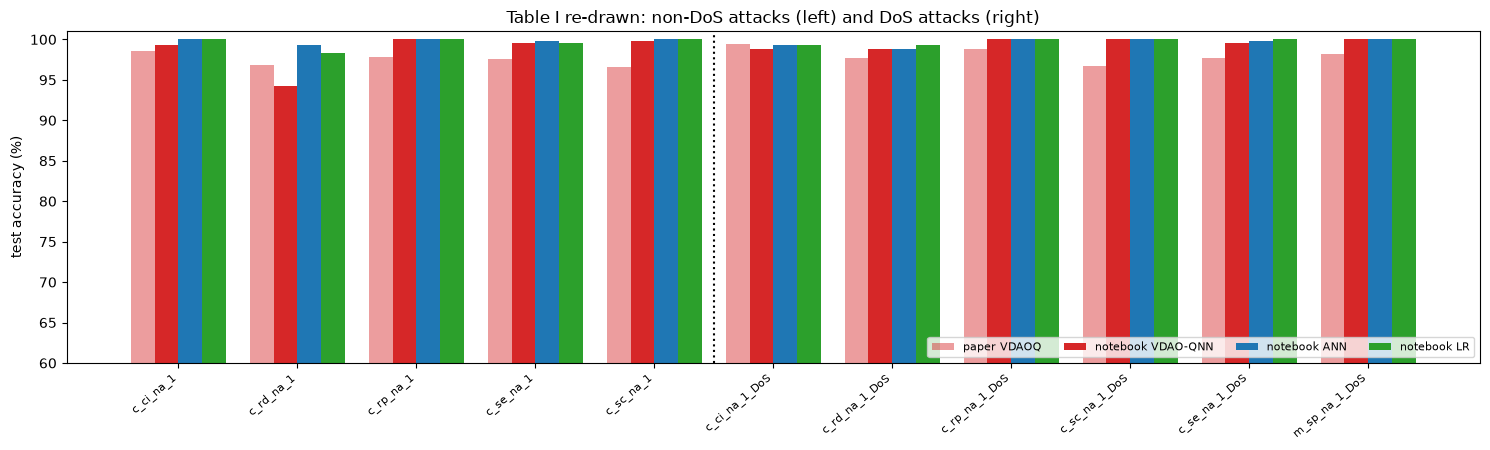

In [14]:
PAPER = pd.DataFrame({
    "LR":   [95.24, 90.64, 91.02, 91.46, 96.00, 99.45, 97.86, 99.17, 98.08, 98.30, 99.78],
    "KNN":  [96.77, 97.15, 96.93, 97.59, 98.35, 99.39, 98.68, 99.01, 98.52, 99.17, 99.07],
    "GNB":  [96.11, 97.538, 91.19, 97.86, 97.26, 98.74, 97.53, 94.09, 97.53, 98.79, 99.78],
    "ANN":  [96.33, 98.03, 97.59, 98.35, 98.80, 99.67, 99.12, 99.72, 94.52, 99.45, 99.83],
    "VDAOQ":[98.52, 96.82, 97.81, 97.59, 96.61, 99.45, 97.70, 98.79, 96.77, 97.70, 98.19]},
    index=["c_ci_na_1", "c_rd_na_1", "c_rp_na_1", "c_se_na_1", "c_sc_na_1", "c_ci_na_1_DoS", "c_rd_na_1_DoS", "c_rp_na_1_DoS", "c_sc_na_1_DoS", "c_se_na_1_DoS", "m_sp_na_1_DoS"])
assert PAPER.index.tolist() == [a for a in ATTACKS[:5]] + ["c_ci_na_1_DoS", "c_rd_na_1_DoS", "c_rp_na_1_DoS", "c_sc_na_1_DoS", "c_se_na_1_DoS", "m_sp_na_1_DoS"]

W = RES[RES.cost == "accuracy-weighted"]
q_mean = (W.groupby("attack").test_acc_vad.mean() * 100).reindex(PAPER.index)
q_std  = (W.groupby("attack").test_acc_vad.std(ddof=0) * 100).reindex(PAPER.index)
cl = BAS[BAS.input == "features"].pivot(index="attack", columns="model", values="acc").reindex(PAPER.index) * 100
T1 = pd.DataFrame({"paper VDAOQ": PAPER.VDAOQ, "notebook VDAO-QNN": q_mean.round(2), "+- std": q_std.round(2),
                   "diff (nb-paper)": (q_mean - PAPER.VDAOQ).round(2),
                   "paper LR": PAPER.LR, "nb LR": cl.LR.round(2), "paper KNN": PAPER.KNN, "nb KNN": cl.KNN.round(2),
                   "paper GNB": PAPER.GNB, "nb GNB": cl.GNB.round(2), "paper ANN": PAPER.ANN, "nb ANN": cl.ANN.round(2)})
display(T1)
print("mean over the 11 attacks - paper VDAOQ: %.2f | notebook VDAO-QNN: %.2f | notebook best classical (RF): %.2f" %
      (PAPER.VDAOQ.mean(), q_mean.mean(), BAS[(BAS.input == 'features') & (BAS.model == 'RF')].acc.mean() * 100))

fig, ax = plt.subplots(figsize=(15, 4.6)); x = np.arange(len(PAPER)); wd = 0.2
ax.bar(x - 1.5 * wd, PAPER.VDAOQ, wd, label="paper VDAOQ", color="tab:red", alpha=0.45)
ax.bar(x - 0.5 * wd, q_mean, wd, yerr=q_std, label="notebook VDAO-QNN", color="tab:red")
ax.bar(x + 0.5 * wd, cl.ANN, wd, label="notebook ANN", color="tab:blue")
ax.bar(x + 1.5 * wd, cl.LR, wd, label="notebook LR", color="tab:green")
ax.set_xticks(x); ax.set_xticklabels(PAPER.index, rotation=40, ha="right", fontsize=8); ax.set_ylim(60, 101); ax.set_ylabel("test accuracy (%)")
ax.axvline(4.5, color="k", ls=":"); ax.set_title("Table I re-drawn: non-DoS attacks (left) and DoS attacks (right)"); ax.legend(fontsize=8, ncol=4, loc="lower right")
plt.tight_layout(); plt.show()

### Confusion matrices, precision, recall, F1 and timing

Attack is the positive class. Counts are for the test flows of the first seed (210 normal + 210 attack flows per problem).

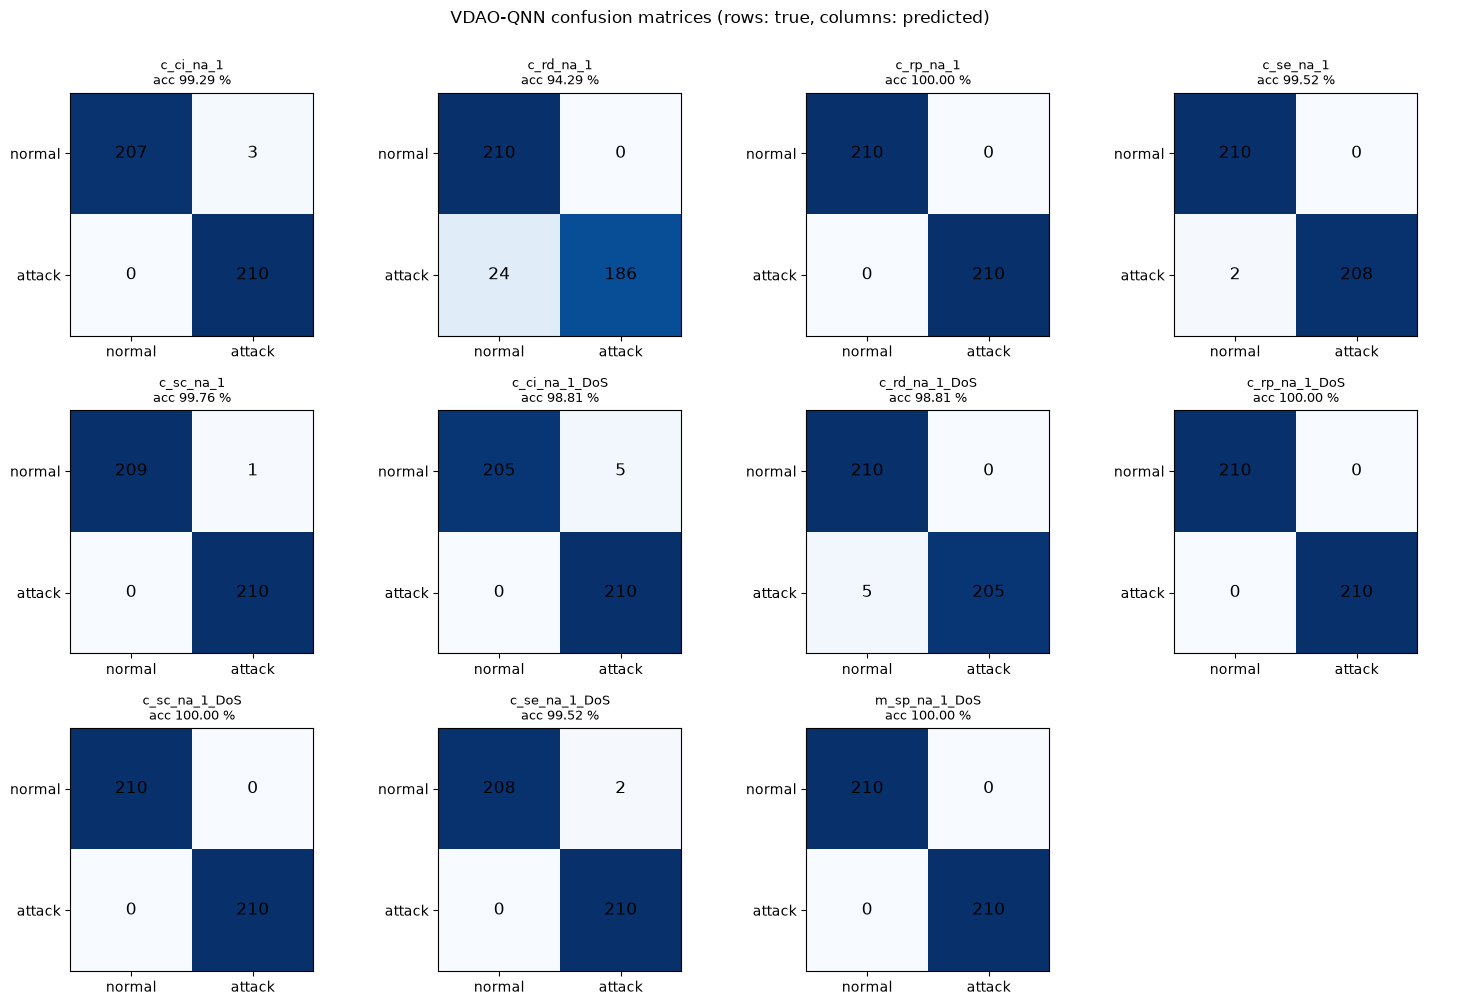

,test_acc_vad,precision,recall,f1,best_epoch,val_acc_vad,out_abs,seconds
attack,,,,,,,,
c_ci_na_1,0.9929,0.9859,1.0000,0.9929,4,0.9848,0.2156,36.6372
c_rd_na_1,0.9429,1.0000,0.8857,0.9394,4,0.9949,0.2212,103.7823
c_rp_na_1,1.0000,1.0000,1.0000,1.0000,4,1.0000,0.2156,32.4361
c_se_na_1,0.9952,1.0000,0.9905,0.9952,4,0.9949,0.2019,25.5701
c_sc_na_1,0.9976,0.9953,1.0000,0.9976,4,0.9797,0.1925,16.5752
c_ci_na_1_DoS,0.9881,0.9767,1.0000,0.9882,4,0.9797,0.2016,22.9328
c_rd_na_1_DoS,0.9881,1.0000,0.9762,0.9880,4,1.0000,0.2018,23.4842
c_rp_na_1_DoS,1.0000,1.0000,1.0000,1.0000,4,1.0000,0.2120,11.5913
c_sc_na_1_DoS,1.0000,1.0000,1.0000,1.0000,4,0.9746,0.2878,24.1658


mean training+selection time per accuracy-weighted run: 33.0 s (classical models: well under 1 s each)


In [15]:
R0 = W[W.seed == SEEDS[0]].set_index("attack").reindex(ATTACKS)
fig, axes = plt.subplots(3, 4, figsize=(15, 10)); axes = axes.ravel()
for ax, att in zip(axes, ATTACKS):
    r = R0.loc[att]; cm = np.array([[r.tn, r.fp], [r.fn, r.tp]])
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=cm.sum() / 2)
    for (i, j), val in np.ndenumerate(cm): ax.text(j, i, int(val), ha="center", va="center", color="black", fontsize=12)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["normal", "attack"]); ax.set_yticks([0, 1]); ax.set_yticklabels(["normal", "attack"])
    ax.set_title(f"{att}\nacc {r.test_acc_vad*100:.2f} %", fontsize=9)
axes[-1].axis("off"); fig.suptitle("VDAO-QNN confusion matrices (rows: true, columns: predicted)", y=1.0)
plt.tight_layout(); plt.show()
display(R0[["test_acc_vad", "precision", "recall", "f1", "best_epoch", "val_acc_vad", "out_abs", "seconds"]].round(4))
print(f"mean training+selection time per accuracy-weighted run: {W.seconds.mean():.1f} s (classical models: well under 1 s each)")

## 7. Ablation 1 (Fig. 7): accuracy-enhancement cost versus plain MSE

Same data order, same initial parameters, same VAD selection; only the cost differs. Left: test accuracy of the VAD-selected
model per attack; right: mean training-batch accuracy per epoch for the paper's example attack.

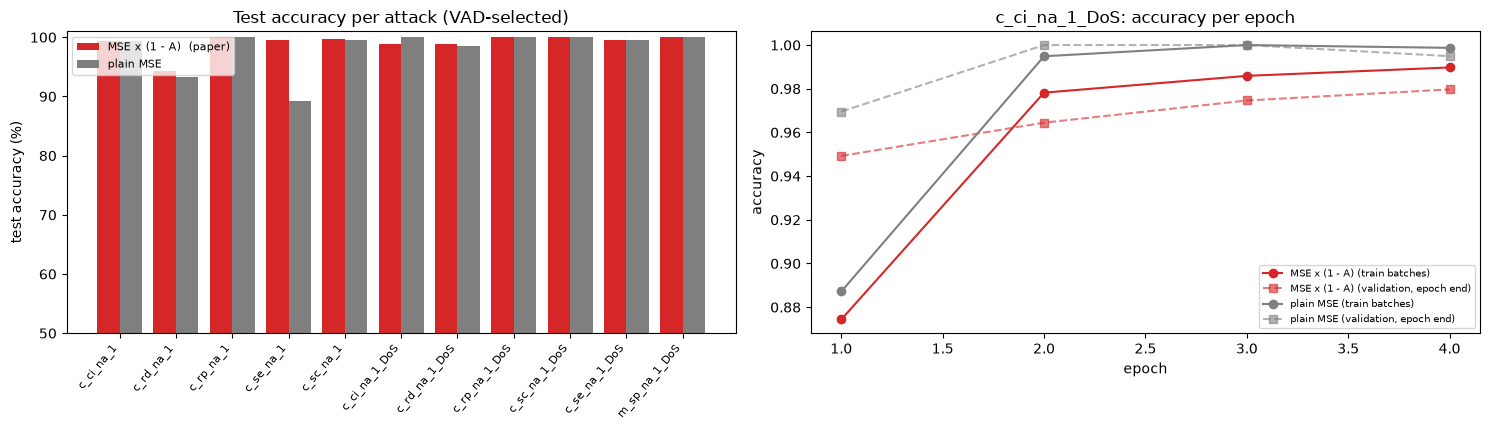

accuracy gain of the weighted cost over plain MSE (points): mean 0.95, median 0.00, attacks improved: 4 / 11, worse: 1


In [16]:
pv = RES.pivot_table(index="attack", columns="cost", values="test_acc_vad", aggfunc="mean").reindex(ATTACKS) * 100
fig, axes = plt.subplots(1, 2, figsize=(15, 4.4))
x = np.arange(len(pv)); axes[0].bar(x - 0.2, pv["accuracy-weighted"], 0.4, label="MSE x (1 - A)  (paper)", color="tab:red")
axes[0].bar(x + 0.2, pv["plain MSE"], 0.4, label="plain MSE", color="tab:gray")
axes[0].set_xticks(x); axes[0].set_xticklabels(pv.index, rotation=50, ha="right", fontsize=8); axes[0].set_ylim(50, 101)
axes[0].set_ylabel("test accuracy (%)"); axes[0].set_title("Test accuracy per attack (VAD-selected)"); axes[0].legend(fontsize=8)
for weighted, c in [(True, "tab:red"), (False, "tab:gray")]:
    e = RUNS[(EXAMPLE_ATTACK, SEEDS[0], weighted)]
    axes[1].plot(np.arange(1, EPOCHS + 1), e["ep_acc"], "-o", color=c, label=("MSE x (1 - A)" if weighted else "plain MSE") + " (train batches)")
    axes[1].plot(np.arange(1, EPOCHS + 1), e["ep_val"], "--s", color=c, alpha=0.6, label=("MSE x (1 - A)" if weighted else "plain MSE") + " (validation, epoch end)")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("accuracy"); axes[1].set_title(f"{EXAMPLE_ATTACK}: accuracy per epoch"); axes[1].legend(fontsize=7)
plt.tight_layout(); plt.show()
d_cost = pv["accuracy-weighted"] - pv["plain MSE"]
print("accuracy gain of the weighted cost over plain MSE (points): mean %.2f, median %.2f, attacks improved: %d / %d, worse: %d" %
      (d_cost.mean(), d_cost.median(), (d_cost > 0).sum(), len(d_cost), (d_cost < 0).sum()))

## 8. Ablation 2 (Fig. 8): best-epoch (VAD) versus final-epoch parameters, and validation-test correlation

The final-epoch model is simply the last parameter set. The VAD model is the best validation configuration of the
best-training epoch. The paper reports that VAD wins on all four attack types it shows and that validation and test accuracy
are strongly correlated for identical parameters.

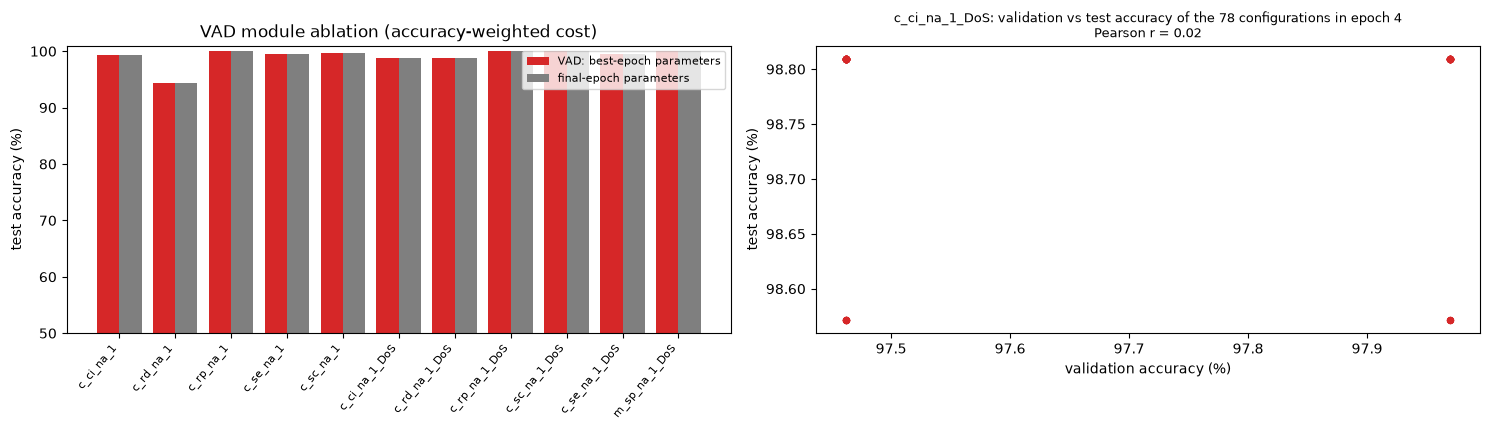

VAD minus final-epoch test accuracy (points): mean 0.00; better on 0, equal on 11, worse on 0 of 11 attacks
on the four types used for Fig. 8 here (c_ci_na_1, c_rd_na_1, c_rp_na_1, c_se_na_1): VAD better on 0 / 4
validation/test Pearson correlation over the epoch's configurations: median 0.02, share of runs with r > 0.5: 18 %


In [17]:
pf = W.groupby("attack")[["test_acc_vad", "test_acc_final"]].mean().reindex(ATTACKS) * 100
fig, axes = plt.subplots(1, 2, figsize=(15, 4.4))
x = np.arange(len(pf)); axes[0].bar(x - 0.2, pf.test_acc_vad, 0.4, label="VAD: best-epoch parameters", color="tab:red")
axes[0].bar(x + 0.2, pf.test_acc_final, 0.4, label="final-epoch parameters", color="tab:gray")
axes[0].set_xticks(x); axes[0].set_xticklabels(pf.index, rotation=50, ha="right", fontsize=8); axes[0].set_ylim(50, 101)
axes[0].set_ylabel("test accuracy (%)"); axes[0].set_title("VAD module ablation (accuracy-weighted cost)"); axes[0].legend(fontsize=8)
e = RUNS[(EXAMPLE_ATTACK, SEEDS[0], True)]
axes[1].scatter(e["vals"] * 100, e["cfg_test"] * 100, s=18, color="tab:red")
axes[1].set_xlabel("validation accuracy (%)"); axes[1].set_ylabel("test accuracy (%)")
axes[1].set_title(f"{EXAMPLE_ATTACK}: validation vs test accuracy of the {len(e['vals'])} configurations in epoch {e['best_ep']+1}\n"
                  f"Pearson r = {W[(W.attack==EXAMPLE_ATTACK)&(W.seed==SEEDS[0])].val_test_corr.iloc[0]:.2f}", fontsize=9)
plt.tight_layout(); plt.show()
d_vad = pf.test_acc_vad - pf.test_acc_final
print("VAD minus final-epoch test accuracy (points): mean %.2f; better on %d, equal on %d, worse on %d of 11 attacks" %
      (d_vad.mean(), (d_vad > 0).sum(), (d_vad == 0).sum(), (d_vad < 0).sum()))
print("on the four types used for Fig. 8 here (%s): VAD better on %d / 4" % (", ".join(FIG8_ATTACKS), (d_vad[FIG8_ATTACKS] > 0).sum()))
print("validation/test Pearson correlation over the epoch's configurations: median %.2f, share of runs with r > 0.5: %.0f %%" %
      (W.val_test_corr.median(), 100 * (W.val_test_corr > 0.5).mean()))

## 9. Fig. 1 and Fig. 6: output near zero, validation accuracy, and gradient statistics

Fig. 1 of the paper says that during training the circuit output stays close to a zero baseline while the validation
accuracy approaches 1. Fig. 6 reports the gradient distribution for a DoS attack: clustered around 0 with a standard
deviation of roughly 0.008, stable over training.

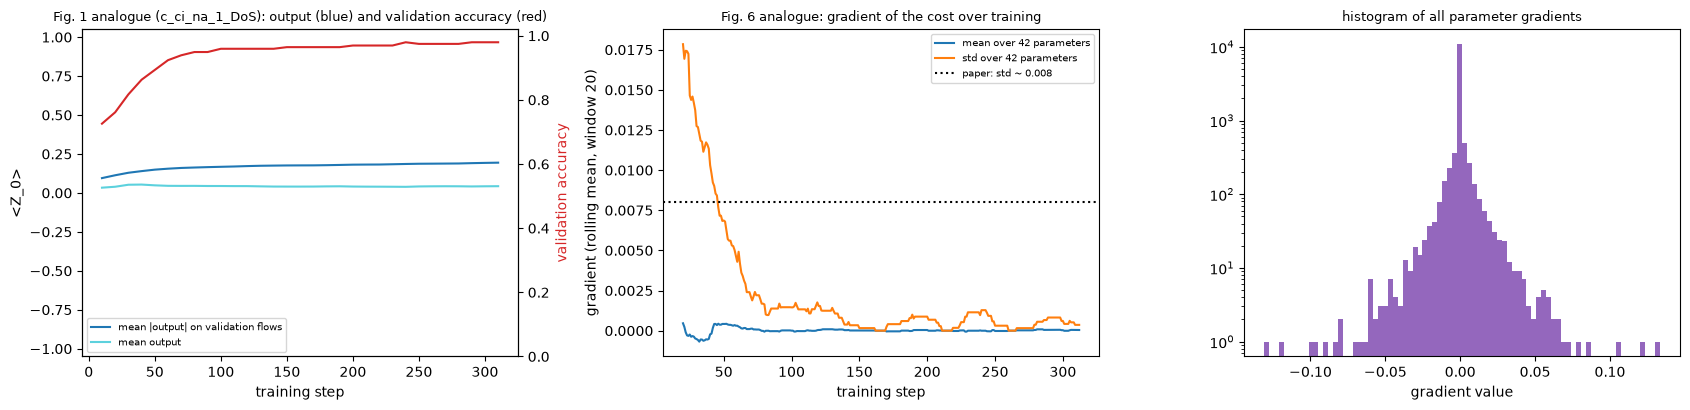

gradient std over all steps/parameters: 0.0069 (first half 0.0096, second half 0.0016); mean 0.00004
final validation accuracy of the traced run: 0.980; mean |output| at the end: 0.194; max validation accuracy seen: 0.980


In [18]:
e = RUNS[(EXAMPLE_ATTACK, SEEDS[0], True)]; tr = e["trace"]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
axes[0].plot(tr[:, 0], tr[:, 2], color="tab:blue", label="mean |output| on validation flows"); axes[0].plot(tr[:, 0], tr[:, 3], color="tab:cyan", alpha=0.7, label="mean output")
axes[0].set_ylabel("<Z_0>"); axes[0].set_xlabel("training step"); axes[0].set_ylim(-1.05, 1.05)
ax2 = axes[0].twinx(); ax2.plot(tr[:, 0], tr[:, 1], color="tab:red", label="validation accuracy"); ax2.set_ylabel("validation accuracy", color="tab:red"); ax2.set_ylim(0, 1.02)
axes[0].set_title(f"Fig. 1 analogue ({EXAMPLE_ATTACK}): output (blue) and validation accuracy (red)", fontsize=9)
axes[0].legend(fontsize=7, loc="lower left")
G = e["grads"]; steps = np.arange(1, len(G) + 1); win = max(20, len(G) // 25)
gm = pd.Series(G.mean(1)).rolling(win).mean(); gs = pd.Series(G.std(1)).rolling(win).mean()
axes[1].plot(steps, gm, label="mean over 42 parameters"); axes[1].plot(steps, gs, label="std over 42 parameters"); axes[1].axhline(0.008, color="k", ls=":", label="paper: std ~ 0.008")
axes[1].set_xlabel("training step"); axes[1].set_ylabel(f"gradient (rolling mean, window {win})"); axes[1].set_title("Fig. 6 analogue: gradient of the cost over training", fontsize=9); axes[1].legend(fontsize=7)
axes[2].hist(G.ravel(), bins=80, color="tab:purple"); axes[2].set_yscale("log"); axes[2].set_xlabel("gradient value"); axes[2].set_title("histogram of all parameter gradients", fontsize=9)
plt.tight_layout(); plt.show()
g_std_all = float(G.std()); g_std_late = float(G[len(G) // 2:].std()); g_std_early = float(G[:len(G) // 2].std())
print(f"gradient std over all steps/parameters: {g_std_all:.4f} (first half {g_std_early:.4f}, second half {g_std_late:.4f}); mean {G.mean():.5f}")
print(f"final validation accuracy of the traced run: {tr[-1,1]:.3f}; mean |output| at the end: {tr[-1,2]:.3f}; max validation accuracy seen: {tr[:,1].max():.3f}")

## 10. Side-by-side comparison with the paper

Rule: **reproduced** when the notebook value is within 2 accuracy points of the paper (0.02 for fractions); otherwise
**not reached** (lower) or **exceeded** (higher) with the gap; **cannot be checked** when the paper gives no number.

In [19]:
def verdict(nb, paper, tol=2.0):
    d = nb - paper
    return "reproduced" if abs(d) <= tol else (f"exceeded (+{d:.1f})" if d > 0 else f"not reached ({d:.1f})")

claims = []
for att in PAPER.index:
    claims.append((f"Table I {att}: VDAO-QNN accuracy", f"{PAPER.VDAOQ[att]:.2f} %", f"{q_mean[att]:.2f} %", verdict(q_mean[att], PAPER.VDAOQ[att])))
claims.append(("Table I: mean VDAO-QNN accuracy over 11 types", f"{PAPER.VDAOQ.mean():.2f} %", f"{q_mean.mean():.2f} %", verdict(q_mean.mean(), PAPER.VDAOQ.mean())))
claims.append(("Minimum accuracy over the 11 types >= 96.61 %", "96.61 %", f"{q_mean.min():.2f} %", "reproduced" if q_mean.min() >= 96.61 - 2.0 else f"not reached ({q_mean.min()-96.61:.1f})"))

nonDoS = ATTACKS[:5]
classical4 = cl[["LR", "KNN", "GNB", "ANN"]]
qnn_best = [(q_mean[a] >= classical4.loc[a].max()) for a in nonDoS]
claims.append(("QNN best of {QNN, LR, KNN, GNB, ANN} on non-DoS types (paper: 2 of 5)", "2 of 5", f"{sum(qnn_best)} of 5",
               "reproduced" if abs(sum(qnn_best) - 2) <= 0 else ("exceeded" if sum(qnn_best) > 2 else "not reached")))
claims.append(("QNN mean accuracy minus mean of the 4 classical models, non-DoS (paper: +%.2f)" % (PAPER.loc[nonDoS, 'VDAOQ'].mean() - PAPER.loc[nonDoS, ['LR', 'KNN', 'GNB', 'ANN']].mean().mean()),
               f"{PAPER.loc[nonDoS,'VDAOQ'].mean() - PAPER.loc[nonDoS,['LR','KNN','GNB','ANN']].mean().mean():+.2f}",
               f"{q_mean[nonDoS].mean() - classical4.loc[nonDoS].mean().mean():+.2f}",
               "reproduced" if (q_mean[nonDoS].mean() - classical4.loc[nonDoS].mean().mean()) > 0 else "not reached"))
spread_q = q_mean.max() - q_mean.min(); spread_p = PAPER.VDAOQ.max() - PAPER.VDAOQ.min()
claims.append(("QNN accuracy is consistent across attack types (spread max-min)", f"{spread_p:.2f} pts", f"{spread_q:.2f} pts",
               "reproduced" if spread_q <= spread_p + 2.0 else f"not reached (spread {spread_q - spread_p:.1f} pts wider)"))
claims.append(("Fig. 7: accuracy-weighted cost better than plain MSE", "better", f"mean {d_cost.mean():+.2f} pts, improved {int((d_cost>0).sum())}/11",
               "reproduced" if d_cost.mean() > 0 and (d_cost > 0).sum() > (d_cost < 0).sum() else "not reached"))
claims.append(("Fig. 8: VAD (best epoch) better than final epoch on the four selected types", "4 of 4", f"{int((d_vad[FIG8_ATTACKS] > 0).sum())} of 4 (mean {d_vad[FIG8_ATTACKS].mean():+.2f} pts)",
               "reproduced" if (d_vad[FIG8_ATTACKS] > 0).all() else "not reached"))
claims.append(("Fig. 8: validation and test accuracy strongly correlated", "strong", f"median r = {W.val_test_corr.median():.2f}", "reproduced" if W.val_test_corr.median() > 0.5 else "not reached"))
claims.append(("Fig. 1: validation accuracy approaches 1", "-> 1", f"{tr[-1,1]:.3f} at the end of the traced run (max {tr[:,1].max():.3f})", "reproduced" if tr[:, 1].max() >= 0.98 else "not reached"))
claims.append(("Fig. 1: output stays near the zero baseline", "|output| small", f"mean |output| {tr[-1,2]:.2f}", "reproduced" if tr[-1, 2] < 0.25 else "not reached"))
claims.append(("Fig. 6: gradient std of the order of 0.008 (factor 2 either way)", "~0.008", f"{g_std_all:.4f} over the whole run",
               "reproduced" if 0.004 <= g_std_all <= 0.016 else ("exceeded" if g_std_all > 0.016 else "not reached")))
claims.append(("Fig. 6: gradient statistics stay stable during training (second-half std >= 50 % of first-half std)", "stable", f"first half {g_std_early:.4f}, second half {g_std_late:.4f}",
               "reproduced" if g_std_late >= 0.5 * g_std_early else "not reached (the gradient shrinks as the batch accuracy A -> 1, by construction of the (1 - A) factor)"))
claims.append(("Speed claims (exponential acceleration), real-hardware performance, other datasets", "stated, no numbers", "-", "cannot be checked"))
COMP = pd.DataFrame(claims, columns=["claim", "paper", "this notebook", "verdict"])
pd.set_option("display.max_colwidth", 90)
display(COMP)
print(COMP.verdict.str.extract(r"^(reproduced|exceeded|not reached|cannot be checked)")[0].value_counts().to_string())
print(f"\ntotal notebook time: {(time.time()-T_NOTEBOOK_START)/60:.1f} min (FAST_MODE={FAST_MODE})")

,claim,paper,this notebook,verdict
0,Table I c_ci_na_1: VDAO-QNN accuracy,98.52 %,99.29 %,reproduced
1,Table I c_rd_na_1: VDAO-QNN accuracy,96.82 %,94.29 %,not reached (-2.5)
2,Table I c_rp_na_1: VDAO-QNN accuracy,97.81 %,100.00 %,exceeded (+2.2)
3,Table I c_se_na_1: VDAO-QNN accuracy,97.59 %,99.52 %,reproduced
4,Table I c_sc_na_1: VDAO-QNN accuracy,96.61 %,99.76 %,exceeded (+3.2)
5,Table I c_ci_na_1_DoS: VDAO-QNN accuracy,99.45 %,98.81 %,reproduced
6,Table I c_rd_na_1_DoS: VDAO-QNN accuracy,97.70 %,98.81 %,reproduced
7,Table I c_rp_na_1_DoS: VDAO-QNN accuracy,98.79 %,100.00 %,reproduced
8,Table I c_sc_na_1_DoS: VDAO-QNN accuracy,96.77 %,100.00 %,exceeded (+3.2)
9,Table I c_se_na_1_DoS: VDAO-QNN accuracy,97.70 %,99.52 %,reproduced


0
reproduced           11
not reached           9
exceeded              3
cannot be checked     1

total notebook time: 18.5 min (FAST_MODE=True)


## 11. Reading the paper critically

* **Which data, which task.** The paper does not say which of the 24 CSV files it used, how a "binary classification" is
  built from a 12-class dataset, how the validation set is formed, or how many epochs were trained. These choices decide
  everything. In this notebook the per-attack binary problems are so easy for the custom IEC-104 features that most
  classical models, even logistic regression, reach 98 to 100 %, **higher** than the classical numbers in the paper's
  Table I (LR 90.6 to 99.8 %). The paper's classical numbers therefore likely come from a different, harder setup
  (other CSV, different split, or no feature scaling for the baselines), and a one-to-one comparison is not possible.
* **Is it a quantum advantage?** No claim of speed or accuracy advantage can be derived from a simulator run on 128
  amplitudes. Amplitude encoding of a classical vector needs a state-preparation circuit that costs `O(2^n)` gates in
  general, so the "exponential reduction of the network scale" is paid for in the data-loading step. The paper itself
  says the QNN is best on only 2 of 5 non-DoS types and loses on the DoS types.
* **The trick is a model-selection trick.** The VAD module picks parameters by validation accuracy among the 78 or so
  configurations of one epoch. This is early stopping / checkpoint selection; the same selection would improve a
  classical network as well, and a fair comparison should apply it to the baselines too. Its gain here is small, and it can
  be noisy because the validation set is small (about 200 flows).
* **The cost function.** Multiplying the MSE by `(1 - A)` rescales the gradient by the current batch error. Because Adam
  normalises gradient magnitudes anyway, the practical effect is mostly to switch off updates on batches that are already
  classified perfectly and to reweight batches; the notebook measures the net effect instead of assuming it.
* **"Gradient around 0.008" is not a trainability proof.** A gradient standard deviation measured on a 7-qubit,
  42-parameter circuit with a local observable says little about barren plateaus, which concern how the variance scales
  with the number of qubits. At 7 qubits the circuit is small enough that no plateau is expected.
* **Closed-set, balanced, lab data.** The balanced package contains the same number of normal and attack flows, from a
  testbed with a handful of hosts. Source/destination identifiers are removed here, but other behavioural fingerprints of the
  testbed may remain, so deployment accuracy would be lower. The paper also notes the lack of other datasets and hardware.

## 12. Exercises

1. **Another CSV.** Set `FEATURE_SET = "cic"` and/or `TIMEOUT_S` to 15, 30, 90, 120 or 180 and rerun. Which choice makes the
   classical baselines look most like the paper's Table I? Does the QNN ranking change?
2. **Circuit design.** Change the rotation gate from `RY` to `RX` followed by `RY`, or add a second parameter per qubit
   and layer, and compare accuracy and gradient statistics. Does the number of parameters (42) matter?
3. **Entanglement skipping.** Replace the sparse coupling of layers 5 and 6 by the full chain (edit `entangler_targets`)
   and rerun the equivalence cell and the ablation. Does the sparse topology help, as the paper argues?
4. **Fair VAD.** Apply the same "best epoch, best validation configuration" selection to the `MLPClassifier` (use
   `partial_fit` and keep the best validation epoch) and compare it with the QNN again.
5. **Noise.** Run the trained circuit with `qml.device("default.mixed", ...)` and a depolarising channel after every CNOT
   (or with a `shots=1000` device) and measure how fast the accuracy falls. How many CNOTs (29 per circuit) can be afforded?